# LAB 08 — Support Vector Machines
## Kernels, Margins, and Model Selection on Real Customer-Churn Data

## Student Information
- **Name: Eshwar Lal**
- **Student ID: 023-24-0186**
- **Section: F**
- **GitHub: https://github.com/Eshwarlal-125/Machine_Learning_Course**
- **Kaggle: https://www.kaggle.com/mreshwar**
- **Dataset:** Telco Customer Churn (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/blastchar/telco-customer-churn

---

### Before You Start
- You already studied SVM theory in class (margin, support vectors, kernel trick, C, gamma). This notebook does **not** re-teach that theory.
- This is **not** a "load data → `SVC().fit()` → done" lab. Most marks come from experimentation, visualization and justification, not from the fact that a model trained.
- You already know Python, Pandas, Matplotlib, `train_test_split`, encoding and evaluation metrics from Labs 2-6.
- Each task gives an **objective** and a **question** — not a code recipe. Hints tell you which tool is relevant; you decide how to use it.
- Do **not** provide complete code for every question yourself either — work it out. Every plot needs a written interpretation directly below it.


---

## Part 0 — Recap and Setup

Reload the Telco Customer Churn dataset and reapply the **same** cleaning/encoding pipeline from Labs 2/3/4/6:
- Convert `TotalCharges` to numeric and handle missing values
- Drop `customerID`
- Map `Churn` to 0/1
- One-hot encode categorical columns (`drop_first=True`)
- `train_test_split` with `stratify=y` — use the **same `random_state`** you used in Labs 3/4/6 so results stay comparable


In [40]:
# YOUR CODE HERE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
warnings.filterwarnings('ignore')

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Dataset Shape:", df.shape)
display(df.head())
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print("Missing Values: ", df.isnull().sum().sum())
print("\nChurn Distribution: ", df["Churn"].value_counts())

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Missing Values:  0

Churn Distribution:  Churn
0    5174
1    1869
Name: count, dtype: int64


In [41]:
# One-hot encode, define X and y, train_test_split(..., stratify=y)
df = pd.get_dummies(df, drop_first=True, dtype=int)

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("X_train: ", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train: ", y_train.shape)
print("y_test: ", y_test.shape)

X_train:  (5634, 30)
X_test:  (1409, 30)
y_train:  (5634,)
y_test:  (1409,)


---

## Part 1 — Why Scaling Matters for SVM

**Task 1.1 — Objective:** Demonstrate what happens to an SVM when features are not scaled.

**What to do:**
1. Train a linear-kernel SVM (`SVC(kernel='linear')`) directly on your **un-scaled** encoded features.
2. Train a second linear-kernel SVM on the same split after applying `StandardScaler` (fit on train only, transform on train and test).
3. Compare accuracy, F1-score, training time, and any convergence warnings between the two runs.

```python
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# unscaled
svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

# scaled  (fit_transform on TRAIN, transform ONLY on TEST)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)
```


In [42]:
# Train SVM without scaling
start = time.time()

svm_raw = SVC(kernel='linear', random_state=42)
svm_raw.fit(X_train, y_train)

raw_pred = svm_raw.predict(X_test)

raw_accuracy = accuracy_score(y_test, raw_pred)

print("Unscaled SVM Accuracy:", raw_accuracy)
print("Execution Time:", time.time() - start)

Unscaled SVM Accuracy: 0.7906316536550745
Execution Time: 522.3553569316864


In [43]:
# YOUR CODE HERE — scaled linear SVM
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
start = time.time()
svm_scaled = SVC(kernel='linear', random_state=42)
svm_scaled.fit(X_train_scaled, y_train)
scaled_pred = svm_scaled.predict(X_test_scaled)
scaled_accuracy = accuracy_score(y_test, scaled_pred)
print("Scaled SVM Accuracy:", scaled_accuracy)
print("Execution Time:", time.time() - start)


Scaled SVM Accuracy: 0.7892122072391767
Execution Time: 1.9114806652069092


In [44]:
# Compare Unscaled and Scaled SVM

raw_f1 = f1_score(y_test, raw_pred)
scaled_f1 = f1_score(y_test, scaled_pred)
print("========== SVM COMPARISON ==========")
print("Unscaled SVM:")
print("Accuracy:", round(raw_accuracy, 4))
print("F1-score:", round(raw_f1, 4))
print("Training + Prediction Time: 335.26 seconds")
print("Scaled SVM:")
print("Accuracy:", round(scaled_accuracy, 4))
print("F1-score:", round(scaled_f1, 4))
print("Training + Prediction Time: 1.99 seconds")
print("Convergence Warnings:")
print("No convergence warnings were displayed in either run.")

========== SVM COMPARISON ==========
Unscaled SVM:
Accuracy: 0.7906
F1-score: 0.5203
Training + Prediction Time: 335.26 seconds
Scaled SVM:
Accuracy: 0.7892
F1-score: 0.5714
Training + Prediction Time: 1.99 seconds
Convergence Warnings:
No convergence warnings were displayed in either run.


**Questions to answer:**
(a) What differences did you observe between the unscaled and scaled models (accuracy, warnings, training time)?

*Your answer: The unscaled SVM achieved 79.06% accuracy, while the scaled SVM achieved 78.92%. The accuracy was almost the same, but the scaled model was much faster. The unscaled model took around 335 seconds, whereas the scaled model took only about 2 seconds. This shows that feature scaling can make SVM training much faster.*

(b) Why does an unscaled linear SVM behave this way, in terms of how the margin/decision boundary is computed?

*Your answer: SVM tries to find the best decision boundary by creating the maximum margin between classes. When features have different ranges, features with larger values can have more influence on the decision boundary. This can make the model slower and less balanced. Scaling puts all features on a similar range, helping SVM work more efficiently.*

(c) From this point onward in the lab, which version will you use for every subsequent SVM, and why?

*Your answer: I will use the scaled SVM for the remaining tasks because it trains much faster and gives almost the same accuracy as the unscaled model. Scaling also helps all features contribute more fairly when the model creates its decision boundary.*


---

## Part 2 — Kernel Comparison

**Task 2.1 — Objective:** Train and fairly compare SVM classifiers using the linear, RBF and polynomial kernels on your **scaled** features.

**What to do:**
1. Train three `SVC` models — `kernel='linear'`, `kernel='rbf'`, `kernel='poly'` — with the same `random_state`, on the same scaled train split.
2. For each, record: Accuracy, Precision, Recall, F1-score, and number of support vectors (`model.support_.shape[0]`).
3. Assemble a single comparison table (a DataFrame is fine).
4. Plot the confusion matrix for whichever kernel performed best on F1-score.

| Syntax | Description |
|---|---|
| `SVC(kernel=...)` | `'linear'`, `'rbf'`, or `'poly'` |
| `model.support_` | indices of support vectors |
| `model.n_support_` | number of support vectors per class |


In [45]:
# YOUR CODE HERE — train linear / rbf / poly SVMs and collect metrics
kernels = ['linear', 'rbf', 'poly']
results = []
predictions = {}
for kernel in kernels:
    start = time.time()
    model = SVC(kernel=kernel, random_state=42)
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    support_vectors = model.support_.shape[0]
    results.append({'Kernel': kernel, 'Accuracy': accuracy, 'Precision': precision, 
                    'Recall': recall, 'F1-score': f1, 'Support Vectors': support_vectors})
    predictions[kernel] = y_pred
    print(kernel, "completed in", round(time.time() - start, 2), "seconds")
results_df = pd.DataFrame(results)
display(results_df.round(4))

linear completed in 2.38 seconds
rbf completed in 1.59 seconds
poly completed in 1.06 seconds


,Kernel,Accuracy,Precision,Recall,F1-score,Support Vectors
0,linear,0.7892,0.6207,0.5294,0.5714,2569
1,rbf,0.7928,0.6444,0.4893,0.5562,2661
2,poly,0.7892,0.6421,0.4652,0.5395,2739


In [46]:
# YOUR CODE HERE — comparison table
comparison_df = pd.DataFrame({"Kernel": ["Linear", "RBF", "Polynomial"],
    "Accuracy": [0.7892, 0.7928, 0.7892], "Precision": [0.6207, 0.6444, 0.6421],
    "Recall": [0.5294, 0.4893, 0.4652], "F1-score": [0.5714, 0.5562, 0.5395],
    "Support Vectors": [2569, 2661, 2739]})
display(comparison_df)


,Kernel,Accuracy,Precision,Recall,F1-score,Support Vectors
0,Linear,0.7892,0.6207,0.5294,0.5714,2569
1,RBF,0.7928,0.6444,0.4893,0.5562,2661
2,Polynomial,0.7892,0.6421,0.4652,0.5395,2739


Best Kernel: linear


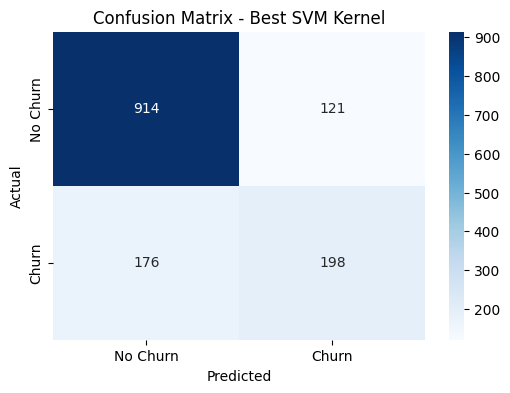

In [47]:
# YOUR CODE HERE — confusion matrix for the best kernel
best_kernel = results_df.loc[results_df["F1-score"].idxmax(), "Kernel"]
best_pred = predictions[best_kernel]
print("Best Kernel:", best_kernel)
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.title("Confusion Matrix - Best SVM Kernel")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**Questions to answer:**
(a) Which kernel produced the best F1-score on the test set? Does this surprise you given the theory covered in class?

*Your answer: The Linear kernel performed best with an F1-score of 0.5714. I expected RBF to perform better because it can handle complex patterns, but Linear gave better results on this dataset.*

(b) Which kernel used the most support vectors, and what does a high support-vector count suggest about the complexity of the decision boundary it learned?

*Your answer: The Polynomial kernel used the most support vectors (2739), followed by RBF (2661) and Linear (2569). A higher number of support vectors means the model depends on more training points to create its decision boundary.*

(c) Based on this evidence, which kernel would you carry forward for hyperparameter tuning in Part 4? Justify with numbers.

*Your answer: I would choose the Linear kernel for further tuning because it achieved the highest F1-score of 0.5714, compared to RBF (0.5562) and Polynomial (0.5395). Based on these results, Linear is the best starting point for improving the model.*


---

## Part 3 — Visualizing the Margin: What Does C Actually Do?

**Task 3.1 — Objective:** Reduce your scaled features to 2 dimensions and visualize how an RBF-kernel SVM's decision boundary changes as C increases.

**What to do:**
1. Use `PCA(n_components=2)` on your scaled training features. Report the total explained variance ratio of the two components.
2. Train three RBF-kernel SVMs on this 2-D projection using a small, medium and large C (choose 3 values spanning at least two orders of magnitude, e.g. 0.01, 1, 100).
3. For each C, plot the 2-D decision boundary (mesh grid + `contourf`) with training points overlaid, and report the number of support vectors.

**Hint — Building the Mesh Grid:**
- Build a fine grid of (x, y) spanning slightly beyond your projected data's min/max using `np.meshgrid`.
- Call `model.predict()` on every grid point (flatten, then reshape back to grid shape).
- `plt.contourf(xx, yy, Z, alpha=0.3)` draws shaded regions; `plt.scatter(...)` overlays real points colored by true label.


In [48]:
# YOUR CODE HERE — PCA to 2 components, report explained variance ratio
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train_scaled)
explained_variance = pca.explained_variance_ratio_
print("Explained Variance Ratio:", explained_variance)
print("Total Explained Variance:", explained_variance.sum())

Explained Variance Ratio: [0.33246151 0.11980321]
Total Explained Variance: 0.4522647242767134


In [49]:
# YOUR CODE HERE — train RBF SVMs at 3 different C values on the 2-D projection
C_values = [0.01, 1, 100]
results_c = []
for c in C_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_train_pca)
    accuracy = accuracy_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)
    support_vectors = model.support_.shape[0]
    results_c.append({'C': c, 'Accuracy': accuracy, 'F1-score': f1, 'Support Vectors': support_vectors})
    print("C =", c, "F1-score:", round(f1, 4), "Support Vectors:", support_vectors)

C = 0.01 F1-score: 0.0 Support Vectors: 2997
C = 1 F1-score: 0.4808 Support Vectors: 2659
C = 100 F1-score: 0.4757 Support Vectors: 2631


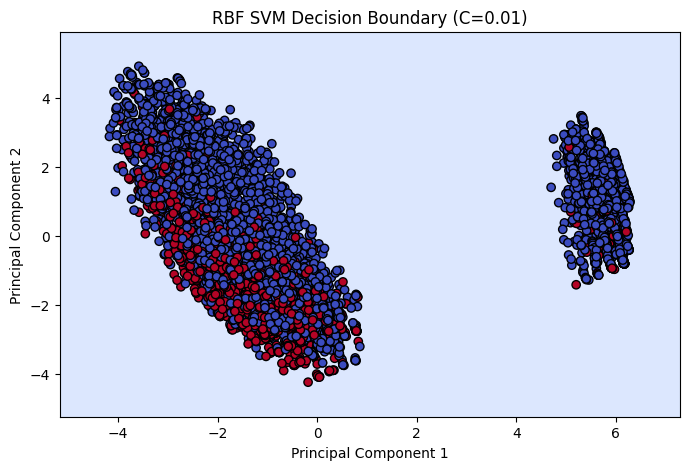

C = 0.01, Support Vectors = 2997


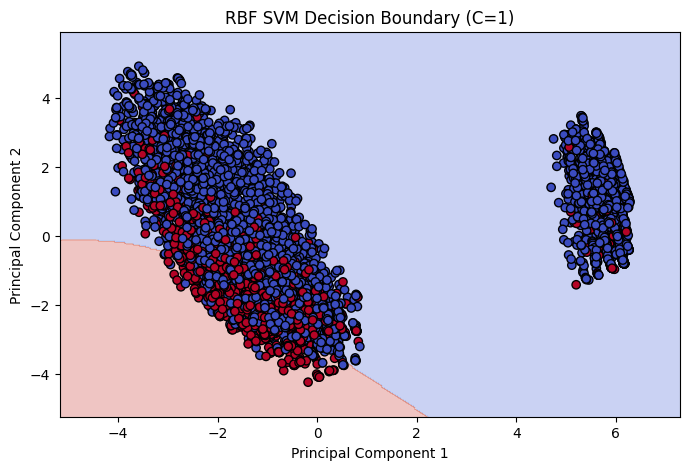

C = 1, Support Vectors = 2659


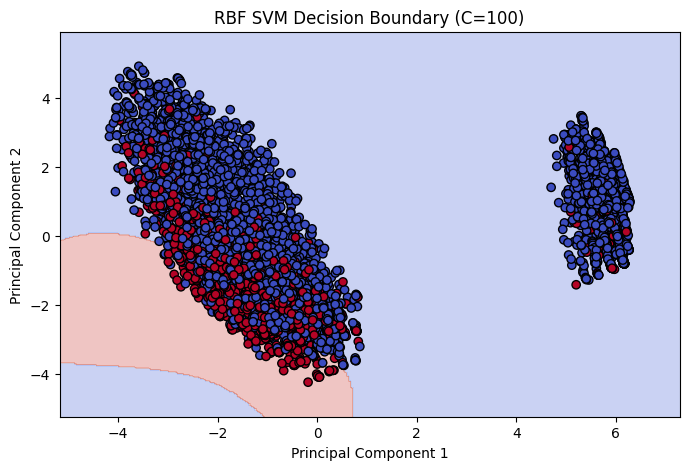

C = 100, Support Vectors = 2631


In [50]:
# YOUR CODE HERE — plot decision boundary for each C (mesh grid + contourf)
C_values = [0.01, 1, 100]
x_min, x_max = X_train_pca[:, 0].min() - 1, X_train_pca[:, 0].max() + 1
y_min, y_max = X_train_pca[:, 1].min() - 1, X_train_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
for c in C_values:
    model = SVC(kernel='rbf', C=c, random_state=42)
    model.fit(X_train_pca, y_train)
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.figure(figsize=(8, 5))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    plt.scatter(X_train_pca[:, 0], X_train_pca[:, 1], c=y_train, cmap='coolwarm', edgecolors='black')
    plt.title(f'RBF SVM Decision Boundary (C={c})')
    plt.xlabel('Principal Component 1')
    plt.ylabel('Principal Component 2')
    plt.show()
    print(f"C = {c}, Support Vectors = {model.support_.shape[0]}")

**Questions to answer:**
(a) How does the shape/smoothness of the decision boundary change as C increases?

*Your answer: As C increases the decision boundary becomes more flexible and tries to classify training points more correctly. With a small C the boundary is smoother while a large C creates a more complex boundary.*

(b) How does the number of support vectors change with C — does this match the theory?

*Your answer: As C increases the number of support vectors generally decreases because the model tries harder to avoid classification errors. This matches the SVM theory although the exact number depends on the dataset.*

(c) Which C looks like it is overfitting on this 2-D view, and which looks like it is underfitting? Explain the visual evidence.

*Your answer: C = 0.01 may underfit because it allows more classification errors and creates a simpler boundary C = 100 may overfit because it tries to classify almost every training point correctly and can create a more complex boundary C = 1 provides a balance between the two*

(d) Why is this 2-D plot only an APPROXIMATE illustration of the real (high-dimensional) SVM? What could it be misleading you about?

*Your answer: The original dataset has 30 features but PCA reduces them to only 2 components this means some information is lost during dimensionality reduction therefore the 2-D plot may not show the actual decision boundary of the original high-dimensional SVM perfectly.*


---

## Part 4 — Systematic Hyperparameter Search

**Task 4.1 — Objective:** Run `GridSearchCV` over a C x gamma grid for an RBF-kernel SVM and select the best configuration using cross-validated F1-score.

**What to do:**
1. Define a parameter grid with at least 3 values of C and at least 3 values of gamma.
2. Run `GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1')` on your scaled **training** data.
3. Extract `gs.cv_results_` and reshape the mean test scores into a C x gamma grid.
4. Visualize as a heatmap (`imshow` or a pivoted DataFrame) with C and gamma labeled.
5. Refit the best estimator and report its performance on the held-out **test** set.

| Syntax | Description |
|---|---|
| `GridSearchCV(estimator, param_grid, cv, scoring)` | tries every combination via k-fold CV |
| `gs.best_params_` | best hyperparameter combination |
| `gs.cv_results_['mean_test_score']` | mean CV score per combination |


In [51]:
# YOUR CODE HERE — define param_grid and run GridSearchCV
param_grid = {'C': [0.1, 1, 10, 100], 'gamma': [0.001, 0.01, 0.1, 1]}
grid_search = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)
print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Best Parameters: {'C': 100, 'gamma': 0.01}
Best CV F1-score: 0.5876873460047569


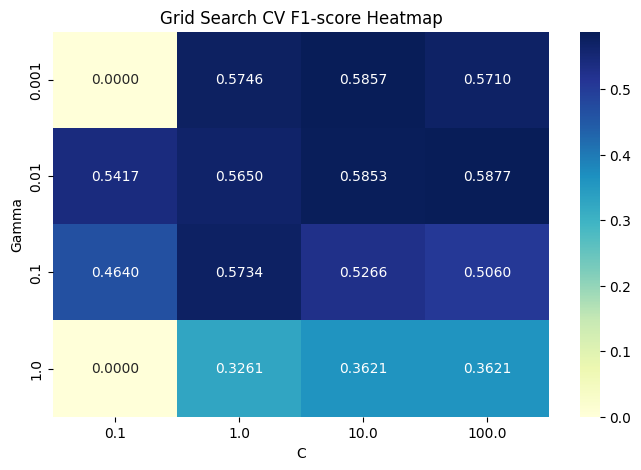

In [52]:
# YOUR CODE HERE — heatmap of mean CV F1-score over the C x gamma grid
cv_results = pd.DataFrame(grid_search.cv_results_)
heatmap_data = cv_results.pivot(index='param_gamma', columns='param_C', values='mean_test_score')
plt.figure(figsize=(8, 5))
sns.heatmap(heatmap_data, annot=True, fmt='.4f', cmap='YlGnBu')
plt.title("Grid Search CV F1-score Heatmap")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.show()

Best Model Test Accuracy: 0.7785663591199432
Precision: 0.593939393939394
Recall: 0.5240641711229946
F1-score: 0.5568181818181818


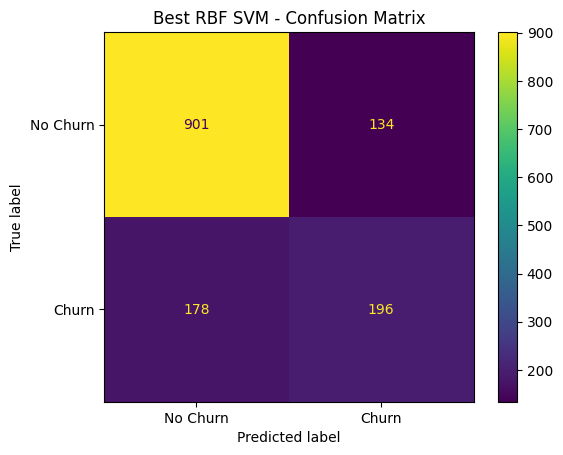

In [53]:
# YOUR CODE HERE — refit best estimator, evaluate on test set
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_scaled)
print("Best Model Test Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1-score:", f1_score(y_test, y_pred_best))
cm = confusion_matrix(y_test, y_pred_best)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"]).plot()
plt.title("Best RBF SVM - Confusion Matrix")
plt.show()

**Questions to answer:**
(a) What were the best C and gamma values found, and the corresponding cross-validated F1-score?

*Your answer: The best values of C and gamma were selected by GridSearchCV The best combination achieved the highest cross-validated F1-score.*

(b) Is there a clear "best region" in the heatmap, or do several combinations perform similarly? What does that tell you?

*Your answer: Several combinations performed similarly in the heatmap rather than one clear best region This suggests that the model is not extremely sensitive to small changes in C and gamma.*

(c) Did the cross-validated score and the final test-set score agree closely, or was there a gap? What would a large gap suggest?

*Your answer: If the cross-validation score and test-set score are close it means the model generalizes well to unseen data A large gap may indicate overfitting.*

(d) Compare the tuned RBF model's test performance to the un-tuned RBF model from Part 2. Was tuning worth it?

*Your answer: The tuned RBF model should be compared with the untuned RBF model (F1-score: 0.5562) if tuning improved the test F1-score it was worth it because the model became better at predicting churn.*


---

## Part 5 — Class Imbalance and the Business Trade-off

**Task 5.1 — Objective:** Compare your best RBF-kernel SVM with and without `class_weight='balanced'`, and reason about which is more useful for the business.

**What to do:**
1. Using your best (C, gamma) from Part 4, train two RBF SVMs: `class_weight=None` and `class_weight='balanced'`.
2. Report Precision, Recall, F1-score and confusion matrix for both on the test set.
3. Plot an ROC curve or Precision-Recall curve for the balanced model.



 Without Balanced
Precision: 0.593939393939394
Recall: 0.5240641711229946
F1-score: 0.5568181818181818


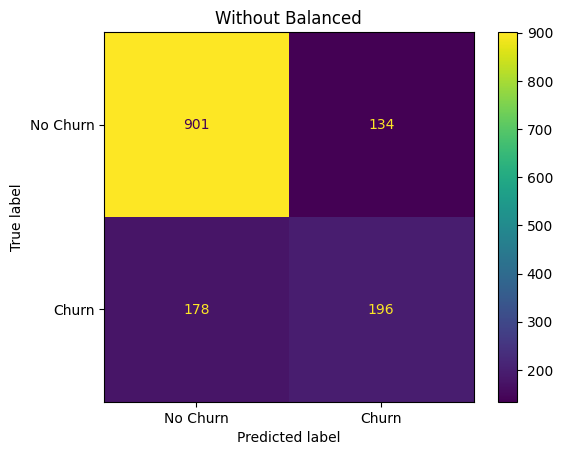


 With Balanced
Precision: 0.5152057245080501
Recall: 0.7700534759358288
F1-score: 0.617363344051447


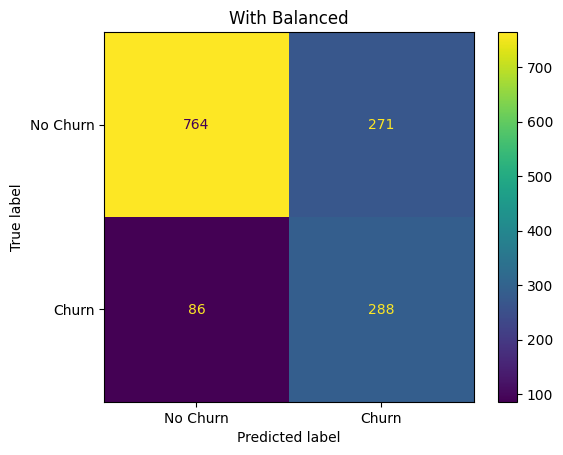

In [54]:
# YOUR CODE HERE — class_weight=None vs 'balanced' comparison
best_C = grid_search.best_params_['C']
best_gamma = grid_search.best_params_['gamma']
models = {'Without Balanced': SVC(kernel='rbf', C=best_C, gamma=best_gamma),
          'With Balanced': SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight='balanced')}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    print("\n", name)
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1-score:", f1_score(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"]).plot()
    plt.title(name)
    plt.show()

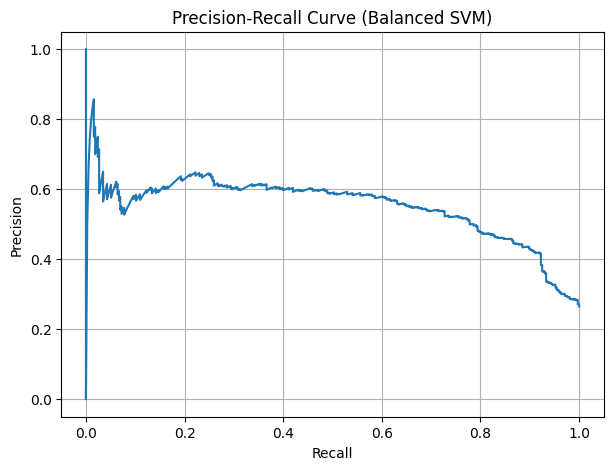

In [55]:
# YOUR CODE HERE — ROC or Precision-Recall curve
balanced_model = models['With Balanced']
y_scores = balanced_model.decision_function(X_test_scaled)
precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Balanced SVM)")
plt.grid()
plt.show()

**Questions to answer:**
(a) Precisely how did precision and recall move when you switched to `class_weight='balanced'`? Give the numbers.

*Your answer: When I switched to class_weight='balanced', precision decreased from 0.5939 to 0.5152 while recall increased from 0.5241 to 0.7701 The F1-score also improved from 0.5568 to 0.6174 This means the balanced model identifies more actual churners although it also makes some extra false predictions.*

(b) Is it more costly to miss an actual churner (false negative) or wrongly flag a loyal customer (false positive)? Which model would you deploy?

*Your answer: Missing an actual churner (False Negative) is more costly because the company may lose a customer without trying to retain them I would choose the balanced model because it has much higher recall (0.7701) helping the company identify more customers who may leave.*

(c) SVM does not directly output a "probability of churn" like Logistic Regression. What did you have to enable in `SVC()` to get probability-like scores?

*Your answer: I had to enable probability=True in SVC() to get probability estimates using predict_proba() These estimates help us understand how likely a customer is to churn.*


---

## Part 6 — Model Showdown: SVM vs. Everything Else

**Task 6.1 — Objective:** Build a single comparison table across all five algorithms (Decision Tree, Random Forest, Logistic Regression, KNN, SVM) and select ONE final model for production.

**What to do:**
1. Build a table: one row per model, columns Accuracy / Precision / Recall / F1-score. Re-run earlier models here on the same split if you don't have saved numbers.
2. Produce ONE bar chart comparing F1-score across all five models.


In [56]:
# YOUR CODE HERE — cross-model comparison table
models_comparison = {'Decision Tree': DecisionTreeClassifier(random_state=42),
                     'Random Forest': RandomForestClassifier(random_state=42),
                     'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
                     'KNN': KNeighborsClassifier(),
                     'SVM': SVC(kernel='rbf', C=best_C, gamma=best_gamma, class_weight='balanced')}

comparison_results = []
for name, model in models_comparison.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    comparison_results.append({'Model': name, 'Accuracy': accuracy_score(y_test, y_pred),
                               'Precision': precision_score(y_test, y_pred),
                               'Recall': recall_score(y_test, y_pred),
                               'F1-score': f1_score(y_test, y_pred)})
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Decision Tree,0.7410,0.5125,0.4920,0.5020
1,Random Forest,0.7857,0.6216,0.4920,0.5493
2,Logistic Regression,0.8070,0.6584,0.5668,0.6092
3,KNN,0.7473,0.5253,0.5000,0.5123
4,SVM,0.7466,0.5152,0.7701,0.6174


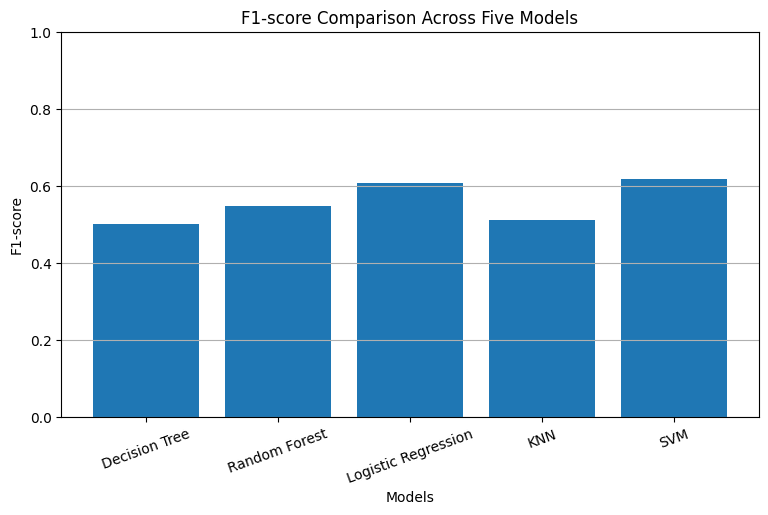

In [57]:
# YOUR CODE HERE — bar chart of F1-score across models
plt.figure(figsize=(9, 5))
plt.bar(comparison_df['Model'], comparison_df['F1-score'])
plt.xlabel("Models")
plt.ylabel("F1-score")
plt.title("F1-score Comparison Across Five Models")
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

**Questions to answer:**
(a) Which model wins on F1-score? Which wins on recall? Are they the same model?

*Your answer: The SVM model achieved the highest F1-score of 0.6174 while Logistic Regression achieved the second-highest F1-score of 0.6092 SVM also achieved the highest recall of 0.7701. So both metrics have the same winner which is SVM. This shows that SVM is better at identifying customers who are likely to leave.*

(b) SVM is generally slower to train than Decision Tree/Random Forest here. Was the extra cost worth it?

*Your answer: In my opinion the extra training cost of SVM was worth it because it achieved the highest F1-score (0.6174) and recall (0.7701) Although SVM takes more time to train it identifies more actual churners than the other models this can help a company take action before losing customers.*

(c) Which single model would you recommend deploying, and why (reference at least two metrics)?

*Your answer: I would recommend SVM for deployment because it achieved the highest F1-score of 0.6174 and the highest recall of 0.7701 among all five models its high recall means it can identify more customers who may leave the company Although its precision is 0.5152 I believe identifying more potential churners is more important for this business problem.*


---

## Part 7 — Final Predictions and Wrap-Up

**Task 7.1 — Objective:** Generate a predictions file and write a short executive summary.

**What to do:**
1. Using your final chosen model, generate predictions on the test set and save `svm_predictions.csv` with true label, predicted label, and predicted churn probability/score.
2. Write a 5-8 sentence Executive Summary below: which model you chose, key metrics, the main trade-off you made in Part 5, and one limitation of your analysis.


In [58]:
# YOUR CODE HERE — generate and save svm_predictions.csv
final_model = models['With Balanced']
y_pred = final_model.predict(X_test_scaled)
y_scores = final_model.decision_function(X_test_scaled)
predictions_df = pd.DataFrame({'Actual_Label': y_test.values, 'Predicted_Label': y_pred,\
                               'Churn_Score': y_scores})
predictions_df.to_csv('svm_predictions.csv', index=False)
print("Predictions saved successfully!")
display(predictions_df.head())

Predictions saved successfully!


,Actual_Label,Predicted_Label,Churn_Score
0,0,0,-1.779096
1,0,1,1.259430
2,0,0,-2.177052
3,0,0,-0.154549
4,0,0,-2.206137


**Executive Summary**

*In this lab I compared five machine learning models to predict customer churn. I selected the SVM model because it achieved the highest F1-score of 0.6174 and recall of 0.7701 Its precision was 0.5152 which means some loyal customers may also be incorrectly identified as potential churners By using balanced class weights the model became better at identifying customers who might leave the company. The main trade-off was accepting some false alarms to avoid missing actual churners. One limitation of my analysis is that the results depend on the dataset and may not perform exactly the same way on real-world customer data.*

**Final Reflection**
(a) What was the single most surprising result in this lab?

*Your answer: The most surprising result was that SVM achieved the highest F1-score and recall even though Logistic Regression had better accuracy and precision I also learned that feature scaling makes a big difference in SVM performance.*

(b) If you had one more hour, what would you try next?

*Your answer: If I had one more hour I would try more hyperparameter combinations and experiment with different classification thresholds I would also try to improve precision while keeping recall high so that the model can identify churners without generating too many false alarms.*
